In [26]:
from astropy import units as u
from astropy import constants as const
import math
import numpy as np
import matplotlib.pyplot as plt

Text(0, 0.5, '$R_g\\,dn/dR_g$')

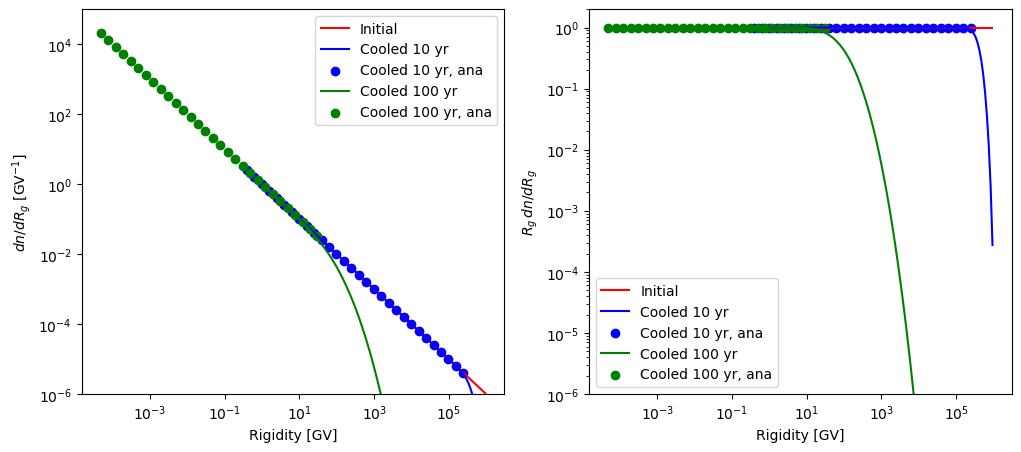

In [27]:
data = np.fromfile("momentum_spectra.bin", dtype=np.float64).reshape(-1, 3)
Rg, initial_t100, cooled_t100 = data.T
data = np.fromfile("momentum_spectra_t10.bin", dtype=np.float64).reshape(-1, 3)
Rg, initial_t10, cooled_t10 = data.T

Rg_ana_t10 = Rg*np.exp(-0.1*10)
Rg_ana_t100 = Rg*np.exp(-0.1*100)

fig, axes = plt.subplots(1,2, figsize=(12,5))
axes[0].plot(Rg, initial_t10, label="Initial", c = "red")
axes[0].plot(Rg, cooled_t10, label="Cooled 10 yr", c = "blue")
axes[0].scatter(Rg_ana_t10[::4], np.e*initial_t10[::4], label="Cooled 10 yr, ana",c = "blue")
axes[0].plot(Rg, cooled_t100, label="Cooled 100 yr", c = "green")
axes[0].scatter(Rg_ana_t100[::4], np.e**10*initial_t100[::4], label="Cooled 100 yr, ana",c = "green")

axes[1].plot(Rg, Rg*initial_t10, label="Initial", c = "red")
axes[1].plot(Rg, Rg*cooled_t10, label="Cooled 10 yr", c = "blue")
axes[1].scatter(Rg_ana_t10[::4], np.e*Rg_ana_t10[::4]*initial_t10[::4], label="Cooled 10 yr, ana",c = "blue")

axes[1].plot(Rg, Rg*cooled_t100, label="Cooled 100 yr",c = "green")
axes[1].scatter(Rg_ana_t100[::4], np.e**10*Rg_ana_t100[::4]*initial_t100[::4], label="Cooled 100 yr, ana",c = "green")

for i in range(2):
    axes[i].set_xscale("log")
    axes[i].set_yscale("log")
    axes[i].set_xlabel("Rigidity [GV]")
    axes[i].legend()
axes[0].set_ylim(1e-6,1e5)
axes[1].set_ylim(1e-6, 2)
axes[0].set_ylabel(r"$dn/dR_g$ [GV$^{-1}$]")
axes[1].set_ylabel(r"$R_g\,dn/dR_g$")


In [28]:
Rg

array([1.05925373e+00, 1.18850223e+00, 1.33352143e+00, 1.49623566e+00,
       1.67880402e+00, 1.88364909e+00, 2.11348904e+00, 2.37137371e+00,
       2.66072506e+00, 2.98538262e+00, 3.34965439e+00, 3.75837404e+00,
       4.21696503e+00, 4.73151259e+00, 5.30884444e+00, 5.95662144e+00,
       6.68343918e+00, 7.49894209e+00, 8.41395142e+00, 9.44060876e+00,
       1.05925373e+01, 1.18850223e+01, 1.33352143e+01, 1.49623566e+01,
       1.67880402e+01, 1.88364909e+01, 2.11348904e+01, 2.37137371e+01,
       2.66072506e+01, 2.98538262e+01, 3.34965439e+01, 3.75837404e+01,
       4.21696503e+01, 4.73151259e+01, 5.30884444e+01, 5.95662144e+01,
       6.68343918e+01, 7.49894209e+01, 8.41395142e+01, 9.44060876e+01,
       1.05925373e+02, 1.18850223e+02, 1.33352143e+02, 1.49623566e+02,
       1.67880402e+02, 1.88364909e+02, 2.11348904e+02, 2.37137371e+02,
       2.66072506e+02, 2.98538262e+02, 3.34965439e+02, 3.75837404e+02,
       4.21696503e+02, 4.73151259e+02, 5.30884444e+02, 5.95662144e+02,
      

In [29]:
Rg_ana_t10

array([3.89677668e-01, 4.37225535e-01, 4.90575119e-01, 5.50434337e-01,
       6.17597484e-01, 6.92955774e-01, 7.77509167e-01, 8.72379634e-01,
       9.78826048e-01, 1.09826089e+00, 1.23226899e+00, 1.38262854e+00,
       1.55133474e+00, 1.74062621e+00, 1.95301473e+00, 2.19131856e+00,
       2.45869987e+00, 2.75870663e+00, 3.09531975e+00, 3.47300588e+00,
       3.89677668e+00, 4.37225535e+00, 4.90575119e+00, 5.50434337e+00,
       6.17597484e+00, 6.92955774e+00, 7.77509167e+00, 8.72379634e+00,
       9.78826048e+00, 1.09826089e+01, 1.23226899e+01, 1.38262854e+01,
       1.55133474e+01, 1.74062621e+01, 1.95301473e+01, 2.19131856e+01,
       2.45869987e+01, 2.75870663e+01, 3.09531975e+01, 3.47300588e+01,
       3.89677668e+01, 4.37225535e+01, 4.90575119e+01, 5.50434337e+01,
       6.17597484e+01, 6.92955774e+01, 7.77509167e+01, 8.72379634e+01,
       9.78826048e+01, 1.09826089e+02, 1.23226899e+02, 1.38262854e+02,
       1.55133474e+02, 1.74062621e+02, 1.95301473e+02, 2.19131856e+02,
      

## 可复现的绝热项定量检查

上面的旧文件比较保留作参考，不能证明当前源码的正确性。以下检查独立编译当前
`momentum_solver.cpp`、`field.cpp` 和 `test_adiabatic.cpp`，不读取或覆盖旧二进制结果。

定义 $q=dn/dR_g$、$a=(\nabla\cdot v)/3$，仅演化动量算子：
$\dot R_g=-aR_g$，$q(R_g,t)=e^{at}q_0(R_ge^{at})$。
与数值解比较时，将初始谱在 $[R_{g,k}e^{at},R_{g,k+1}e^{at}]$ 上积分，
再除以当前单元宽度；积分限截在初始有限定义域 $[1,10^6]$ GV。
这里没有额外空间稀释因子。

采用局域对数高斯谱和 $R_g^{-2}$ 谱，避开 $R_g^{-1}$ 的稳态退化。
覆盖膨胀、压缩、圆柱轴、非均匀空间网格、径向/竖直散度、边界流失和时间/刚度收敛。
测试容差针对下方指定网格与小时间步；不宣称 CN 在任意步长下保持非负。

In [30]:
from pathlib import Path
import io
import math
import subprocess
import tempfile
import numpy as np
import matplotlib.pyplot as plt

root = Path.cwd()
build_dir = tempfile.TemporaryDirectory(prefix="adiabatic_check_")
exe = Path(build_dir.name) / "test_adiabatic"
subprocess.run(["c++", "-std=c++20", "-O2", "-I", str(root),
                str(root / "test_adiabatic.cpp"), str(root / "momentum_solver.cpp"),
                str(root / "field.cpp"), "-o", str(exe)], check=True)

def run_case(cells=240, steps=1000, time=10.0, a=0.1,
             profile="peak", boundary="outflow", wind="both"):
    result = subprocess.run([str(exe), str(cells), str(steps), str(time),
                             str(a), profile, boundary, wind],
                            check=True, capture_output=True, text=True)
    N0, N, escaped, spatial_error, ghost = map(float, result.stdout.splitlines()[0][2:].split())
    lo, hi, Rg, initial, final = np.loadtxt(io.StringIO(result.stdout)).T
    width = hi - lo
    # Conservation uses the time-centred numerical boundary flux, matching CN.
    assert abs(N + escaped - N0) / N0 < 2e-11, "boundary flux balance"
    assert spatial_error / max(np.max(np.abs(final)), 1e-300) < 2e-12, "spatial divergence"
    assert ghost == 7.0, "spatial ghost modified"
    assert final.min() >= -1e-13 * initial.max(), "small-step positivity"
    return dict(lo=lo, hi=hi, Rg=Rg, width=width, initial=initial, final=final,
                N0=N0, N=N, escaped=escaped, time=time, a=a, profile=profile)

def exact_average(case):
    lo = np.clip(case["lo"] * np.exp(case["a"]*case["time"]), 1.0, 1e6)
    hi = np.clip(case["hi"] * np.exp(case["a"]*case["time"]), 1.0, 1e6)
    if case["profile"] == "power":
        integral = 1/lo - 1/hi
    elif case["profile"] == "cutoff":
        integral = np.log(hi/lo)
    else:
        cdf = lambda x: np.array([0.5*math.erf(math.log(v/1000)/(math.sqrt(2)*0.5)) for v in x])
        integral = cdf(hi) - cdf(lo)
    return integral / case["width"]

def l1_error(case):
    exact = exact_average(case)
    return np.sum(np.abs(case["final"]-exact)*case["width"]) / np.sum(exact*case["width"])

In [31]:
# All three velocity fields have div(v)=3*a, including the cylindrical axis.
reference = run_case()
for wind in ("radial", "vertical"):
    case = run_case(wind=wind)
    np.testing.assert_allclose(case["final"], reference["final"], rtol=2e-12, atol=1e-15)
identity = run_case(a=0.0)
np.testing.assert_array_equal(identity["final"], identity["initial"])

# Peak location of Rg*q and its log-rigidity centroid both shift by -a*t.
peaks = [run_case(cells=960, a=a) for a in (0.1, -0.1)]
for case in peaks:
    expected_log_peak = math.log(1000) - case["a"]*case["time"]
    log_peak = np.log(case["Rg"][np.argmax(case["Rg"]*case["final"])])
    centroid = np.sum(np.log(case["Rg"])*case["final"]*case["width"])/case["N"]
    assert abs(log_peak - expected_log_peak) < 0.04, "peak cooling/heating rate"
    assert abs(centroid - expected_log_peak) < 0.02, "centroid cooling/heating rate"
    assert abs(case["N"]/case["N0"] - 1) < 1e-9, "isolated peak number"
    print(f'a={case["a"]:+.1f}/yr: peak={np.exp(log_peak):.3f} GV, '
          f'exact={np.exp(expected_log_peak):.3f} GV, L1={l1_error(case):.4g}')

# Rg^-2 changes amplitude as exp(-a*t), unlike Rg^-1.
for a in (0.1, -0.1):
    case = run_case(cells=960, a=a, profile="power")
    interior = (case["Rg"] > 100) & (case["Rg"] < 1000)
    ratio = case["final"][interior] / case["initial"][interior]
    assert np.max(np.abs(ratio / np.exp(-a*case["time"]) - 1)) < 0.025
    print(f'Rg^-2, a={a:+.1f}/yr: amplitude={ratio.mean():.6f}, exact={np.exp(-a*case["time"]):.6f}')

# Closed momentum boundaries conserve number; outflow loses it.
closed = run_case(profile="cutoff", boundary="closed", time=100)
assert abs(closed["N"]/closed["N0"] - 1) < 2e-11
for a in (0.1, -0.1):
    case = run_case(cells=960, steps=10000, time=100, a=a, profile="cutoff")
    exact_ratio = max(0.0, 1-abs(a)*case["time"]/np.log(1e6))
    assert case["escaped"] > 0
    assert abs(case["N"]/case["N0"] - exact_ratio) < 0.007
    print(f'Outflow a={a:+.1f}/yr: N/N0={case["N"]/case["N0"]:.6f}, exact={exact_ratio:.6f}')
print("散度、零风恒等、谱峰/幅度、边界守恒与小步长非负检查通过。")

a=+0.1/yr: peak=373.143 GV, exact=367.879 GV, L1=0.02874
a=-0.1/yr: peak=2718.786 GV, exact=2718.282 GV, L1=0.02887
Rg^-2, a=+0.1/yr: amplitude=0.373173, exact=0.367879
Rg^-2, a=-0.1/yr: amplitude=2.757971, exact=2.718282
Outflow a=+0.1/yr: N/N0=0.281372, exact=0.276176
Outflow a=-0.1/yr: N/N0=0.270955, exact=0.276176
散度、零风恒等、谱峰/幅度、边界守恒与小步长非负检查通过。


cells, relative L1 error: [(np.int64(120), np.float64(0.19359285176424348)), (np.int64(240), np.float64(0.10603982298127432)), (np.int64(480), np.float64(0.0559124471429433)), (np.int64(960), np.float64(0.02873918387905823))]
observed rigidity orders: [0.86841952 0.92336477 0.9601504 ]
CN time orders: [1.98673886 1.99673509]


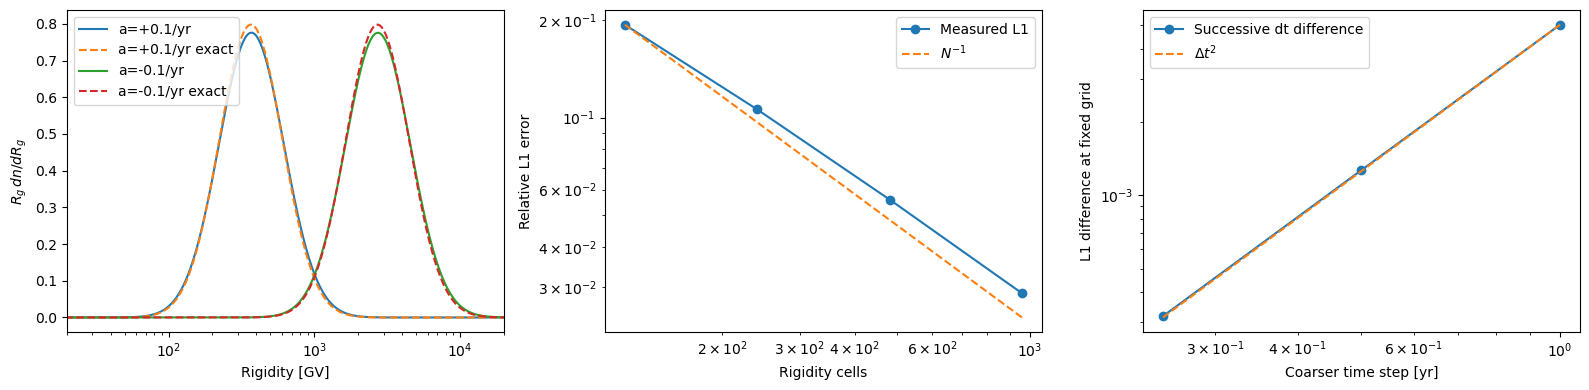

In [32]:
# Refine rigidity at fixed small dt: first-order upwind error should decrease.
resolutions = np.array([120, 240, 480, 960])
refined = [run_case(cells=int(n)) for n in resolutions]
errors = np.array([l1_error(case) for case in refined])
orders = np.log2(errors[:-1]/errors[1:])
assert np.all(np.diff(errors) < 0)
assert np.all(orders[-2:] > 0.7), "rigidity convergence"
print("cells, relative L1 error:", list(zip(resolutions, errors)))
print("observed rigidity orders:", orders)

# Hold the rigidity grid fixed and compare successive dt differences.
# This isolates CN time accuracy from the nonzero rigidity discretization error.
time_cases = [run_case(cells=240, steps=s) for s in (10, 20, 40, 80)]
differences = np.array([np.sum(np.abs(x["final"]-y["final"])*x["width"])
                        for x, y in zip(time_cases[:-1], time_cases[1:])])
time_orders = np.log2(differences[:-1]/differences[1:])
assert np.all((time_orders > 1.8) & (time_orders < 2.2)), "adiabatic CN time order"
print("CN time orders:", time_orders)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for case in peaks:
    label = f'a={case["a"]:+.1f}/yr'
    axes[0].plot(case["Rg"], case["Rg"]*case["final"], label=label)
    axes[0].plot(case["Rg"], case["Rg"]*exact_average(case), "--", label=label+" exact")
axes[0].set_xscale("log")
axes[0].set_xlabel("Rigidity [GV]")
axes[0].set_ylabel(r"$R_g\,dn/dR_g$")
axes[0].set_xlim(20, 20000)
axes[0].legend()
axes[1].loglog(resolutions, errors, "o-", label="Measured L1")
axes[1].loglog(resolutions, errors[0]*resolutions[0]/resolutions, "--", label=r"$N^{-1}$")
axes[1].set_xlabel("Rigidity cells")
axes[1].set_ylabel("Relative L1 error")
axes[1].legend()
axes[2].loglog([1, 0.5, 0.25], differences, "o-", label="Successive dt difference")
axes[2].loglog([1, 0.5, 0.25], differences[0]*np.array([1, 0.5, 0.25])**2, "--", label=r"$\Delta t^2$")
axes[2].set_xlabel("Coarser time step [yr]")
axes[2].set_ylabel("L1 difference at fixed grid")
axes[2].legend()
plt.tight_layout()
plt.show()

### 检查结果与精度限制
本次运行全部断言通过。120、240、480、960 个刚度单元的局域谱相对 L1 误差分别约为 19.36%、10.60%、5.59%、2.87%，最后一次加密的收敛阶为 0.960；绝热 CN 时间收敛阶为 1.987、1.997。
这些结果支持当前绝热通量、散度和边界装配的正确性，同时显示一阶迎风格式仍有数值扩散。100 年的边界流失测试在 960 单元下，粒子数比例与解析值仍相差约 0.0052；通过容差不代表截断被精确输运。

## 常数 Dpp 的随机加速检查

使用当前 `test_momentum_1.cpp`：刚度范围 1–100 GV，初始为中心 20 GV、
标准差 2 GV 的高斯谱，在几何中心采样初始化；风速为零，$D_{pp}=D=1$ GV²/yr，
两端扩散零通量（零风速下 Outflow 不产生绝热流出），保存 1、5、10 yr。所有数据在临时目录重新生成，不使用旧二进制文件。

求解的是 $\partial_tq=\partial_R[D\partial_Rq-2Dq/R]$，不是普通一维热方程。
因此既有展宽也有向高刚度的漂移。零通量边界下 $N=\int q\,dR$ 守恒。
积分分部给出精确有限域矩关系
$ d\langle R^2\rangle/dt=6D-2D[Rq]_{1}^{100}/N$。
以下局域谱在 10 yr 内远离边界，采用忽略边界项的 $\Delta\langle R^2\rangle\simeq6Dt$
检查；同时输出边界尾部，避免将此近似当作任意有限域的精确恒等式。

刚度收敛使用 1024 单元的数值参考，并保守合并到粗网格；它验证数值自收敛，
不是独立解析谱验证。另用 $q_k=R_{g,k}^2$ 检查离散零通量平衡态。
测试源文件保持原有 main、循环和三列二进制输出结构。notebook 仅在临时副本替换参数，分别编译各个测试，不修改源文件。


In [33]:
from pathlib import Path
import subprocess
import re
import tempfile
import numpy as np
import matplotlib.pyplot as plt

stochastic_dir = tempfile.TemporaryDirectory(prefix="constant_Dpp_")
stochastic_path = Path(stochastic_dir.name)
stochastic_exe = stochastic_path / "test_momentum_1"
root = Path.cwd()
source = (root / "test_momentum_1.cpp").read_text()

def stochastic_run(cells, dt=0.001, profile="gaussian", times=(1, 5, 10), lower=1.0, upper=100.0):
    snapshots = {}
    for time in times:
        case_dir = stochastic_path / f"n{cells}_dt{dt}_{profile}_t{time}_R{lower}_{upper}"
        case_dir.mkdir(exist_ok=True)
        # Replace active statements by their role, independent of current values.
        # Fail at setup if the source interface changes, instead of silently
        # running a different grid/time or reading the wrong output filename.
        def replace_statement(pattern, replacement, text):
            updated, count = re.subn(pattern, lambda match: replacement, text,
                                     flags=re.MULTILINE)
            if count != 1:
                raise ValueError(f"Expected one active statement: {pattern}; found {count}")
            return updated

        case_source = replace_statement(
            r"^    const auto Rg = RgGrid::logarithmic\([^;]+;",
            f"    const auto Rg = RgGrid::logarithmic({cells+1}, {lower}, {upper});", source)
        case_source = replace_statement(
            r"^    cr_momentum::Solver cooling\([^;]+;",
            f"    cr_momentum::Solver cooling(grid, Rg, vr, vz, Dpp, {dt}, cr_momentum::Boundary::Outflow, cr_momentum::Boundary::Outflow);",
            case_source)
        case_source = replace_statement(
            r"^    for \(int t = 0; t < [^;]+; \+\+t\)",
            f"    for (int t = 0; t < {round(time/dt)}; ++t)", case_source)
        case_source = replace_statement(
            r'^    std::ofstream output\("[^"\n]+"[^;]+;',
            '    std::ofstream output("spectrum.bin", std::ios::binary | std::ios::trunc);',
            case_source)
        if profile == "equilibrium":
            case_source = replace_statement(
                r"^                q\(k, i, j\) = [^;]+;[^\n]*",
                "                q(k, i, j) = std::pow(Rg.center(k), 2.0);", case_source)
        cpp = case_dir / "test_momentum_1.cpp"
        cpp.write_text(case_source)
        executable = case_dir / "test"
        subprocess.run(["c++", "-std=c++20", "-O2", "-I", str(root), str(cpp),
                        str(root/"momentum_solver.cpp"), str(root/"field.cpp"),
                        "-o", str(executable)], check=True)
        subprocess.run([str(executable)], cwd=case_dir, check=True)
        R, initial, final = np.fromfile(case_dir/"spectrum.bin",
                                        dtype=np.float64).reshape(-1,3).T
        faces = np.geomspace(lower, upper, cells+1)
        snapshots[time] = np.column_stack((faces[:-1], faces[1:], R, initial, final))
    return snapshots

def stochastic_moments(data):
    lo, hi, R, initial, final = data.T
    width = hi-lo
    N0, N = np.sum(initial*width), np.sum(final*width)
    # Integrate R^2 exactly for the piecewise-constant numerical density.
    R2 = (lo*lo + lo*hi + hi*hi)/3
    delta_R2 = np.sum(final*width*R2)/N - np.sum(initial*width*R2)/N0
    return N0, N, delta_R2

stochastic_grids = (128, 256, 512, 1024)
stochastic_cases = {n: stochastic_run(n) for n in stochastic_grids}
print("cells  time  relative number error  delta<R^2>  expected  relative moment error")
for cells, snapshots in stochastic_cases.items():
    for t, data in snapshots.items():
        N0, N, delta = stochastic_moments(data)
        expected = 6.0*t
        assert abs(N/N0-1) < 1e-9, "number conservation"
        assert data[:,4].min() >= -1e-12*data[:,3].max(), "small-step positivity"
        assert abs(delta/expected-1) < 0.02, "second-moment growth"
        print(f"{cells:4d}  {t:2d}  {N/N0-1:+.3e}  {delta:.7f}  {expected:.1f}  {delta/expected-1:+.3e}")

fine = stochastic_cases[1024][10]
N0, N, delta = stochastic_moments(fine)
# R*q/N at each boundary gives the magnitude scale of the moment boundary term.
print("10 yr boundary R*q/N (center estimates):", fine[[0,-1],2]*fine[[0,-1],4]/N)
assert np.max(np.abs(fine[[0,-1],2]*fine[[0,-1],4]/N)) < 1e-5

cells  time  relative number error  delta<R^2>  expected  relative moment error
 128   1  +1.399e-14  6.0061510  6.0  +1.025e-03
 128   5  +8.460e-14  30.0307549  30.0  +1.025e-03
 128  10  +1.836e-13  60.0615169  60.0  +1.025e-03
 256   1  +2.554e-14  6.0015373  6.0  +2.562e-04
 256   5  +1.024e-13  30.0076864  30.0  +2.562e-04
 256  10  +1.743e-13  60.0153797  60.0  +2.563e-04
 512   1  -9.881e-15  6.0003843  6.0  +6.405e-05
 512   5  -5.651e-14  30.0019215  30.0  +6.405e-05
 512  10  -1.231e-13  60.0038498  60.0  +6.416e-05
1024   1  +4.441e-16  6.0000961  6.0  +1.601e-05
1024   5  -6.661e-16  30.0004804  30.0  +1.601e-05
1024  10  -5.884e-15  60.0009676  60.0  +1.613e-05
10 yr boundary R*q/N (center estimates): [2.38147065e-06 1.58967331e-53]


Relative L1 errors against 1024 cells: {128: np.float64(0.002957495624444688), 256: np.float64(0.0007025052511216363), 512: np.float64(0.00014052276478044757)}
Second-moment errors: [np.float64(0.0010252824899916746), np.float64(0.000256327689150293), np.float64(6.416340832982037e-05), np.float64(1.6126988321207847e-05)]
CN time order: 2.000004993264601
Discrete equilibrium maximum relative change: 4.404254738687996e-13


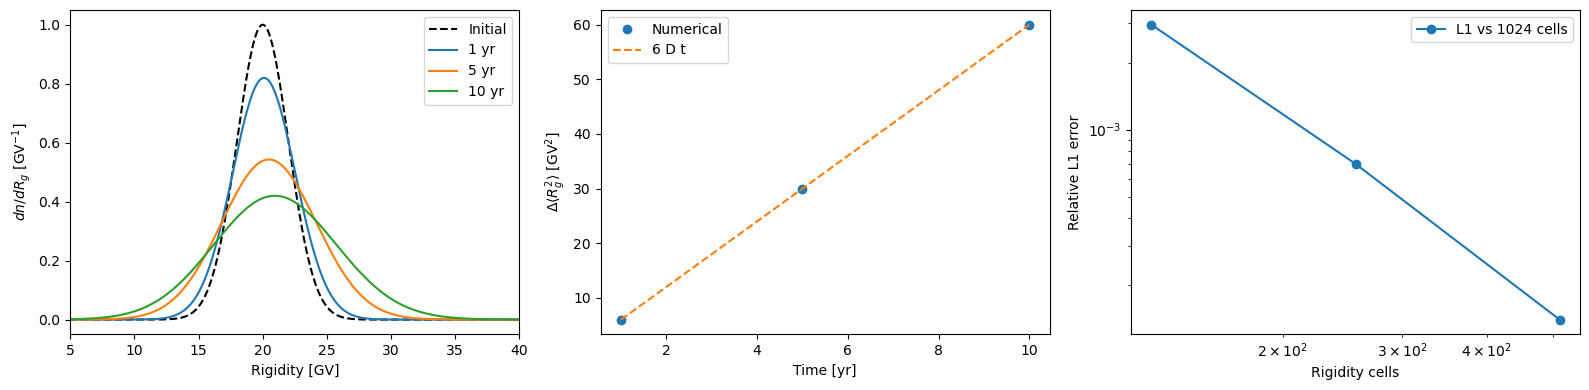

Constant-Dpp stochastic acceleration checks passed.


In [34]:
# Conservatively restrict the fine solution: nested logarithmic faces match.
relative_errors = []
for cells in stochastic_grids[:-1]:
    coarse = stochastic_cases[cells][10]
    factor = 1024//cells
    mass = (fine[:,4]*(fine[:,1]-fine[:,0])).reshape(cells, factor).sum(axis=1)
    reference_average = mass/(coarse[:,1]-coarse[:,0])
    relative_errors.append(np.sum(np.abs(coarse[:,4]-reference_average)*(coarse[:,1]-coarse[:,0]))/N)
assert np.all(np.diff(relative_errors) < 0), "rigidity self-convergence"
moment_errors = [abs(stochastic_moments(stochastic_cases[n][10])[2]/60-1) for n in stochastic_grids]
assert np.all(np.diff(moment_errors) < 0), "second-moment convergence"
print("Relative L1 errors against 1024 cells:", dict(zip(stochastic_grids[:-1], relative_errors)))
print("Second-moment errors:", moment_errors)

# At fixed grid, successive timestep differences isolate CN time accuracy.
time_dts = (0.01, 0.005, 0.0025)
time_solutions = [stochastic_run(256, dt)[10] for dt in time_dts]
time_diffs = [np.sum(np.abs(a[:,4]-b[:,4])*(a[:,1]-a[:,0]))
              for a,b in zip(time_solutions[:-1],time_solutions[1:])]
time_order = np.log2(time_diffs[0]/time_diffs[1])
assert 1.8 < time_order < 2.2, "diffusion CN time order"
print("CN time order:", time_order)

stationary = stochastic_run(256, profile="equilibrium")[10]
equilibrium_error = np.max(np.abs(stationary[:,4]/stationary[:,3]-1))
assert equilibrium_error < 1e-9, "q/Rg^2 equilibrium"
print("Discrete equilibrium maximum relative change:", equilibrium_error)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(fine[:,2], fine[:,3], "k--", label="Initial")
for t, data in stochastic_cases[512].items():
    axes[0].plot(data[:,2], data[:,4], label=f"{t} yr")
axes[0].set(xlim=(5, 40), xlabel="Rigidity [GV]", ylabel=r"$dn/dR_g$ [GV$^{-1}$]")
axes[0].legend()
times = np.array([1,5,10])
axes[1].plot(times, [stochastic_moments(stochastic_cases[512][int(t)])[2] for t in times], "o", label="Numerical")
axes[1].plot(times, 6*times, "--", label="6 D t")
axes[1].set(xlabel="Time [yr]", ylabel=r"$\Delta\langle R_g^2\rangle$ [GV$^2$]")
axes[1].legend()
axes[2].loglog(stochastic_grids[:-1], relative_errors, "o-", label="L1 vs 1024 cells")
axes[2].set(xlabel="Rigidity cells", ylabel="Relative L1 error")
axes[2].legend()
plt.tight_layout()
plt.show()
print("Constant-Dpp stochastic acceleration checks passed.")

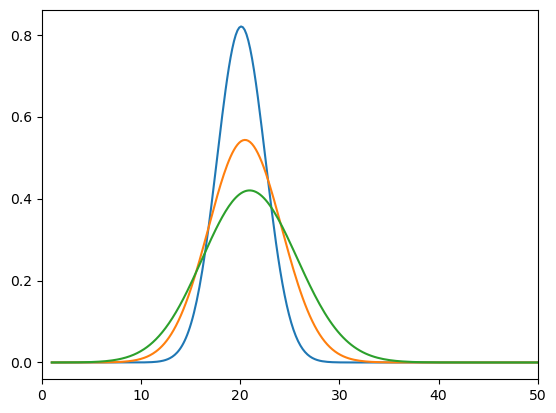

In [35]:

for i in [1, 5, 10]:
    x = stochastic_cases[512][i][:,2]
    y = stochastic_cases[512][i][:,4]
    plt.plot(x,y)
    plt.xlim(0,50)

In [36]:
for i in [1, 5, 10]:
    arr = stochastic_cases[512][i][:,4]
    ind = np.where(arr == np.max(arr))
    print(ind)

(array([333]),)
(array([335]),)
(array([338]),)


In [37]:
stochastic_cases[512][i][333,2]

np.float64(20.0786437860241)

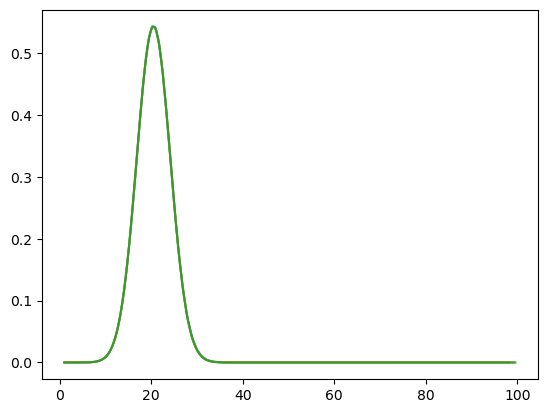

In [38]:

for i in [128, 256, 512]:
    x = stochastic_cases[i][5][:,2]
    y = stochastic_cases[i][5][:,4]
    plt.plot(x,y)

## 512 单元：50、100 yr 的漂移、展宽与解析谱

保持 $D=1$ GV²/yr、初始中心 20 GV、标准差 2 GV；增加 50、100 yr。
这里比较均值与标准差，不把曲线峰位当作均值。

常数 $D$ 时令 $u=q/R$，则 $\partial_tu=D\partial_R^2u$。
在半无限域 $R>0$、原点正则且无穷远衰减的条件下，奇延拓热核给出
$$K(R,s,t)=\frac{R}{s\sqrt{4\pi Dt}}
\left[e^{-(R-s)^2/(4Dt)}-e^{-(R+s)^2/(4Dt)}\right],\quad
q(R,t)=\int_0^\infty K(R,s,t)q_0(s)\,ds.$$
这包含向高刚度的漂移和扩散，不是简单移动的高斯。
解析参考按数值初态的分段常数重建积分，再在目标单元积分取平均，避免中心采样混入初态误差。

**边界区别：**当前模拟是 [1,100] GV 的零通量边界，热核是 [0,∞) 的解。
长时间下两者并不严格相同，因此另做 [0.1,200] GV、同为 512 单元的边界敏感性比较。
此比较也改变了对数网格步长，不能将两次误差之差全部归因于边界。
解析均值和标准差使用半无限域的矩积分，不对有限绘图区重新归一化。

In [39]:
long_times = (1, 5, 10, 50, 100)
stochastic_cases[512].update(stochastic_run(512, times=long_times))
long_control = stochastic_run(512, times=long_times, lower=0.1, upper=200.0)

from numpy.polynomial.legendre import leggauss
from scipy.special import erf

# Gaussian quadrature on the piecewise-constant numerical initial density.
def source_quadrature(data, order=6):
    z, w = leggauss(order)
    lo, hi = data[:,0], data[:,1]
    s = ((lo+hi)[:,None]/2 + (hi-lo)[:,None]*z/2).ravel()
    weights = ((hi-lo)[:,None]*w/2 * data[:,3,None]).ravel()
    # Cells with exactly zero initial mass contribute nothing.
    mask = weights != 0
    return s[mask], weights[mask]

def kernel_average(data, time, order=6):
    s, weights = source_quadrature(data, order)
    z, w = leggauss(order)
    r = ((data[:,0]+data[:,1])[:,None]/2
         + (data[:,1]-data[:,0])[:,None]*z/2)
    result = np.empty(len(data))
    for k in range(len(data)):
        rr = r[k,:,None]
        # expm1 avoids cancellation of the image term near the origin.
        kernel = (rr/s/np.sqrt(4*np.pi*time)
                  * np.exp(-(rr-s)**2/(4*time))
                  * (-np.expm1(-rr*s/time)))
        result[k] = np.sum((kernel @ weights)*w)/2
    return result

def analytic_moments(data, time):
    s, mass = source_quadrature(data)
    # Conditional mean of the 3D radial diffusion kernel; D=1 GV^2/yr.
    b = np.sqrt(time)
    conditional_mean = ((s+2*time/s)*erf(s/(2*b))
                        + 2*b/np.sqrt(np.pi)*np.exp(-s*s/(4*time)))
    N = mass.sum()
    mean = np.sum(mass*conditional_mean)/N
    second = np.sum(mass*(s*s+6*time))/N
    return mean, np.sqrt(second-mean*mean)

def numerical_moments(data):
    lo, hi, R, initial, q = data.T
    mass = q*(hi-lo)
    N = mass.sum()
    mean = np.sum(mass*(lo+hi)/2)/N
    second = np.sum(mass*(lo*lo+lo*hi+hi*hi)/3)/N
    return mean, np.sqrt(second-mean*mean)

long_exact = {}
print("domain [GV]  time  mean_num  mean_ana  sigma_num  sigma_ana  relative_L1")
for domain, snapshots in (("1–100", stochastic_cases[512]), ("0.1–200", long_control)):
    for t in long_times:
        data = snapshots[t]
        exact = kernel_average(data, t)
        long_exact[domain,t] = exact
        width = data[:,1]-data[:,0]
        N0 = np.sum(data[:,3]*width)
        N = np.sum(data[:,4]*width)
        mean, sigma = numerical_moments(data)
        mean_a, sigma_a = analytic_moments(data,t)
        error = np.sum(np.abs(data[:,4]-exact)*width)/N0
        assert abs(N/N0-1) < 1e-8, "long-time number conservation"
        assert data[:,4].min() >= -1e-12*data[:,3].max()
        assert abs(mean/mean_a-1) < 0.005, "mean drift"
        assert abs(sigma/sigma_a-1) < 0.005, "diffusive broadening"
        assert error < 0.005, "spectrum vs half-line kernel"
        # Analytic mass outside this finite domain quantifies domain truncation.
        missing_mass = 1-np.sum(exact*width)/N0
        print(f"{domain:>7}  {t:3d}  {mean:.6f}  {mean_a:.6f}  {sigma:.6f}  {sigma_a:.6f}  {error:.3e}")
        print(f"  analytic mass outside domain={missing_mass:.3e}; numerical boundary R*q/N={data[[0,-1],2]*data[[0,-1],4]/N}")

# Quadrature refinement isolates integration error from solver/domain errors.
for t in long_times:
    data = stochastic_cases[512][t]
    refined_kernel = kernel_average(data,t,order=10)
    difference = np.sum(np.abs(refined_kernel-long_exact['1–100',t])*(data[:,1]-data[:,0]))
    assert difference/np.sum(data[:,3]*(data[:,1]-data[:,0])) < 1e-9
print("512-cell long-time spectrum, mean drift and broadening checks passed.")

domain [GV]  time  mean_num  mean_ana  sigma_num  sigma_ana  relative_L1
  1–100    1  20.101236  20.101234  2.439589  2.439530  6.000e-04
  analytic mass outside domain=-4.441e-16; numerical boundary R*q/N=[3.05139147e-015 1.72220343e-130]
  1–100    5  20.505371  20.505359  3.680026  3.679832  3.571e-04
  analytic mass outside domain=5.276e-09; numerical boundary R*q/N=[2.19891663e-08 7.31900743e-72]
  1–100   10  21.010534  21.010509  4.751022  4.750728  2.341e-04
  analytic mass outside domain=6.894e-07; numerical boundary R*q/N=[2.39987800e-06 6.81663923e-48]
  1–100   50  24.980161  24.979660  8.945784  8.945807  1.056e-04
  analytic mass outside domain=3.815e-05; numerical boundary R*q/N=[1.16397258e-04 2.39537351e-12]
  1–100  100  29.475998  29.475051  11.628916  11.628941  8.050e-05
  analytic mass outside domain=3.496e-05; numerical boundary R*q/N=[1.05972344e-04 4.35530330e-06]
0.1–200    1  20.101588  20.101582  2.440672  2.440511  1.633e-03
  analytic mass outside domain=

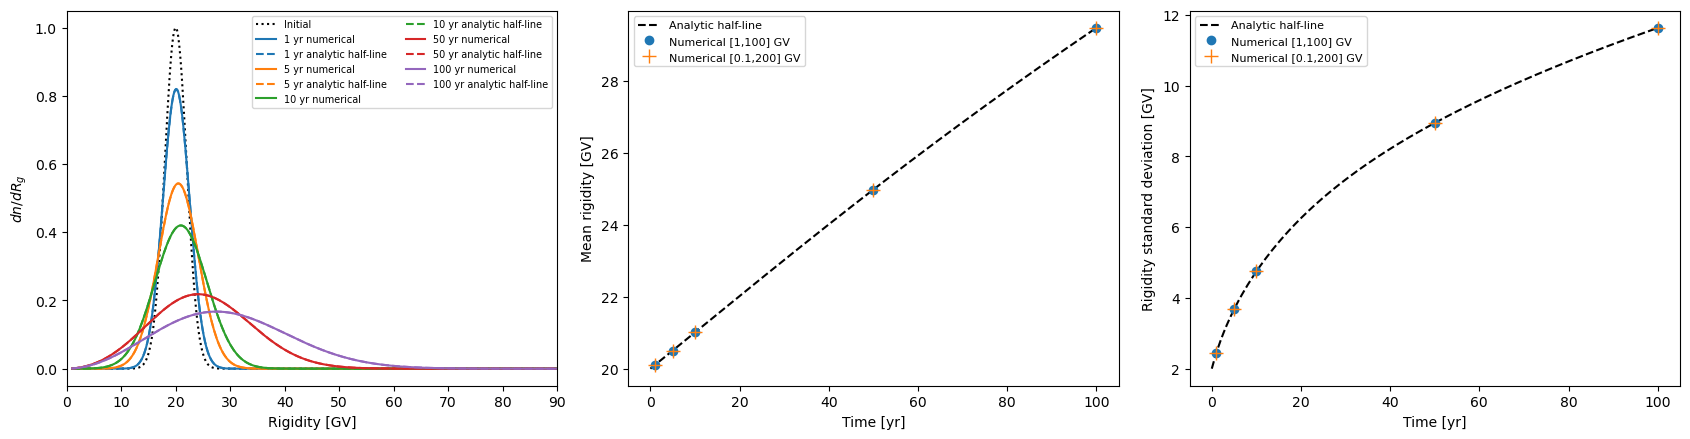

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
data0 = stochastic_cases[512][10]
axes[0].plot(data0[:,2],data0[:,3],"k:",label="Initial")
plot_times = np.array([1, 5, 10, 50, 100])
colors = plt.get_cmap("tab10").colors
for index, t in enumerate(plot_times):
    color = colors[index]
    data = stochastic_cases[512][t]
    axes[0].plot(data[:,2],data[:,4],color=color,label=f"{t} yr numerical")
    axes[0].plot(data[:,2],long_exact['1–100',t],"--",color=color,label=f"{t} yr analytic half-line")
axes[0].set(xlabel="Rigidity [GV]",ylabel=r"$dn/dR_g$",xlim=(0,90))
axes[0].legend(fontsize=7, ncol=2)
plot_times = np.array([1,5,10,50,100])
num_stats = np.array([numerical_moments(stochastic_cases[512][int(t)]) for t in plot_times])
curve_times = np.linspace(0.01,100,150)
ana_stats = np.array([analytic_moments(data0,t) for t in curve_times])
for ax,col,label in ((axes[1],0,"Mean rigidity [GV]"),(axes[2],1,"Rigidity standard deviation [GV]")):
    ax.plot(curve_times,ana_stats[:,col],"k--",label="Analytic half-line")
    ax.plot(plot_times,num_stats[:,col],"o",label="Numerical [1,100] GV")
    control_stats = np.array([numerical_moments(long_control[t]) for t in long_times])
    ax.plot(long_times,control_stats[:,col],"+",ms=10,label="Numerical [0.1,200] GV")
    ax.set(xlabel="Time [yr]",ylabel=label)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()